# Prueba OSM — Medellín

**Pregunta:** ¿OpenStreetMap sirve para armar la red vial de Medellín con sentido de circulación, y qué tanto coincide con la capa oficial de la Alcaldía?

**Qué mide:**
1. Cuántos kilómetros de calles para carros trae OSM dentro del límite IGAC de Medellín.
2. Cuántos tienen el sentido **declarado**, cuántos **implícito** (autopistas y glorietas) y cuántos **sin etiqueta** (en OSM, sin etiqueta = doble vía por convención).
3. Restricciones de giro, puentes y túneles.
4. Tramo por tramo contra la capa «Sentido vial» de la Alcaldía que ya está congelada: dónde coinciden y dónde no.

**Garantías:**
- **No sobrescribe nada.** Cada ejecución crea una carpeta nueva `salidas_medellin_prueba_osm/AAAAMMDD_HHMMSS/` al lado del cuaderno, y cada archivo se abre en modo «crear»: si ya existiera, falla en vez de pisarlo.
- **Lo que ya existe solo se lee**: el límite del IGAC y la capa de la Alcaldía congelada. Si alguna de las dos no está, el cuaderno sigue y avisa.
- Autocontenido: no importa `constantes`, `constantes_d1` ni `d2_medellin`.

**Único ajuste:** revisar las rutas de la celda 1.

**Ojo al interpretar:** la capa de la Alcaldía se construyó a partir de OSM, así que no son fuentes independientes. Una coincidencia alta puede ser copia, no confirmación en campo.

In [1]:
# Celda 1 — Configuración (lo único que hay que revisar)
from pathlib import Path

# --- Archivos que YA existen: solo se leen, nunca se modifican ---
RUTA_LIMITE_IGAC   = Path(r"F:\Tesis\Bloque A\Municipios_Junio_2026.gpkg")
CAPA_LIMITE        = "Munpio"
COLUMNA_CODIGO     = "MpCodigo"
CODIGO_MEDELLIN    = "05001"

RUTA_CRUDO_ALCALDIA = Path(r"F:\Tesis\Grafo Bogotá\datos_crudos\medellin\sentido_vial_med_2026-09-21")

# Para reutilizar una descarga OSM de una ejecución anterior de ESTE cuaderno
# (evita volver a pedirle a Overpass). None = descargar de nuevo.
REUSAR_DESCARGA_OSM = None   # ej.: Path(r"...\salidas_medellin_prueba_osm\20260922_101500\osm_crudo_medellin.json")

# Respaldo si no se encuentra el límite IGAC (mismo bbox de AREAS_ESTUDIO del Bloque A)
BBOX_RESPALDO = dict(oeste=-75.7193, sur=6.1629, este=-75.4718, norte=6.3748)

EPSG_METRICO          = 9377   # MAGNA-SIRGAS Origen Nacional, la convención del proyecto
DIST_EMPAREJAMIENTO_M = 10.0   # distancia máxima para emparejar un tramo de la Alcaldía con una vía OSM
USER_AGENT            = "Tesis-UExternado-ruteo-VE/1.0 (prueba OSM Medellin)"


In [2]:
# Celda 2 — Utilidades y carpeta de salida nueva
import json, hashlib, time
from datetime import datetime, timezone, timedelta
import numpy as np
import pandas as pd
import geopandas as gpd
import requests
from pyproj import Geod
from shapely.geometry import LineString, MultiLineString
from shapely.strtree import STRtree

TZ = timezone(timedelta(hours=-5))
EJECUCION = datetime.now(TZ).strftime("%Y%m%d_%H%M%S")
SALIDA = Path.cwd() / "salidas_medellin_prueba_osm" / EJECUCION
SALIDA.mkdir(parents=True, exist_ok=False)   # carpeta nueva: si existiera, falla en vez de mezclar
ESCRITOS = []                                 # registro de todo lo que escribe este cuaderno

def sha256_bytes(b: bytes) -> str:
    return hashlib.sha256(b).hexdigest()

def sha256_archivo(ruta) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

def escribir_nuevo(nombre: str, contenido):
    """Escribe SOLO dentro de SALIDA y SOLO si el archivo no existe (modo 'x')."""
    ruta = SALIDA / nombre
    if isinstance(contenido, str):
        contenido = contenido.encode("utf-8")
    with open(ruta, "xb") as f:
        f.write(contenido)
    ESCRITOS.append(ruta)
    return ruta

def guardar_csv(df: pd.DataFrame, nombre: str):
    return escribir_nuevo(nombre, df.to_csv(index=False))

def unir(geoserie):
    return geoserie.union_all() if hasattr(geoserie, "union_all") else geoserie.unary_union

def ahora():
    return datetime.now(TZ).isoformat(timespec="seconds")

print("Salida de esta ejecución:", SALIDA)


Salida de esta ejecución: f:\Tesis\Grafo Bogotá\salidas_medellin_prueba_osm\20260925_011846


In [3]:
# Celda 3 — Límite IGAC de Medellín (solo lectura)
if RUTA_LIMITE_IGAC.exists():
    municipios = gpd.read_file(RUTA_LIMITE_IGAC, layer=CAPA_LIMITE)
    sel = municipios[municipios[COLUMNA_CODIGO].astype(str).str.zfill(5) == CODIGO_MEDELLIN]
    assert len(sel) == 1, f"Se esperaba 1 registro con {COLUMNA_CODIGO}={CODIGO_MEDELLIN}, hay {len(sel)}"
    limite = gpd.GeoDataFrame(geometry=[unir(sel.to_crs(EPSG_METRICO).geometry)], crs=EPSG_METRICO)
    area_km2 = limite.area.iloc[0] / 1e6
    print(f"Límite IGAC: {area_km2:.1f} km² (oficial 380,6)")
    assert 360 < area_km2 < 400, "El límite no parece ser solo Medellín"
    FUENTE_LIMITE = "IGAC"
    HASH_LIMITE = sha256_archivo(RUTA_LIMITE_IGAC)
    oeste, sur, este, norte = limite.to_crs(4326).total_bounds
    margen = 0.005   # ~500 m, para no cortar vías justo en el borde antes del recorte fino
    oeste, sur, este, norte = oeste - margen, sur - margen, este + margen, norte + margen
else:
    print("⚠ No se encontró el límite IGAC: se usa solo el rectángulo de respaldo (incluye municipios vecinos).")
    limite, FUENTE_LIMITE, HASH_LIMITE = None, "bbox de respaldo", None
    oeste, sur, este, norte = (BBOX_RESPALDO[k] for k in ["oeste", "sur", "este", "norte"])
print(f"Área de consulta: oeste {oeste:.4f}, sur {sur:.4f}, este {este:.4f}, norte {norte:.4f}")


Límite IGAC: 373.4 km² (oficial 380,6)
Área de consulta: oeste -75.7243, sur 6.1588, este -75.4678, norte 6.3788


In [4]:
# Celda 4 — Descarga de OSM por Overpass (se congela con huella)
CONSULTA = f"""[out:json][timeout:600];
way["highway"]({sur},{oeste},{norte},{este});
out tags geom;
relation["type"="restriction"]({sur},{oeste},{norte},{este});
out tags;"""

SERVIDORES = ["https://overpass-api.de/api/interpreter",
              "https://overpass.kumi.systems/api/interpreter"]

if REUSAR_DESCARGA_OSM is not None:
    contenido = Path(REUSAR_DESCARGA_OSM).read_bytes()
    origen, servidor, fecha_descarga = "reutilizada", None, None
    print("Reutilizando:", REUSAR_DESCARGA_OSM)
else:
    contenido, ultimo_error = None, None
    for servidor in SERVIDORES:
        for intento in range(3):
            try:
                fecha_descarga = ahora()
                r = requests.post(servidor, data={"data": CONSULTA},
                                  headers={"User-Agent": USER_AGENT}, timeout=900)
                r.raise_for_status()
                contenido = r.content
                break
            except Exception as e:
                ultimo_error = e
                time.sleep(10 * (intento + 1))
        if contenido is not None:
            break
    if contenido is None:
        raise RuntimeError(f"Ningún servidor Overpass respondió: {ultimo_error}")
    origen = "descargada"

datos = json.loads(contenido)
# Overpass puede responder 200 con un error dentro (timeout, memoria): se rechaza.
if datos.get("remark"):
    raise RuntimeError(f"Overpass devolvió un aviso de error: {datos['remark']}")
escribir_nuevo("osm_crudo_medellin.json", contenido)

fecha_osm = datos.get("osm3s", {}).get("timestamp_osm_base")
manifiesto_osm = {
    "origen": origen, "servidor": servidor, "fecha_descarga": fecha_descarga,
    "estado_del_mapa_osm": fecha_osm, "consulta_overpass": CONSULTA,
    "archivo": "osm_crudo_medellin.json", "sha256": sha256_bytes(contenido),
    "bytes": len(contenido), "n_elementos": len(datos["elements"]),
    "licencia": "ODbL 1.0 — © colaboradores de OpenStreetMap",
    "limite": FUENTE_LIMITE, "sha256_archivo_limite": HASH_LIMITE,
}
escribir_nuevo("manifiesto_osm.json", json.dumps(manifiesto_osm, ensure_ascii=False, indent=2))
print(f"{origen}: {len(contenido)/1e6:.1f} MB, {len(datos['elements']):,} elementos")
print("Estado del mapa OSM:", fecha_osm)
print("sha256:", manifiesto_osm["sha256"])


descargada: 36.3 MB, 59,064 elementos
Estado del mapa OSM: 2026-09-25T06:17:59Z
sha256: df94efc8068bbc0a841dc1f470cbe6f20b5ea9713ebbcef64fe6d62c8294b57c


In [5]:
# Celda 5 — Vías de OSM dentro de Medellín y clasificación
ETIQUETAS = ["highway", "oneway", "junction", "name", "access", "motor_vehicle",
             "motorcar", "vehicle", "bridge", "tunnel", "layer", "lanes", "maxspeed", "surface"]

filas, geoms = [], []
for el in datos["elements"]:
    if el["type"] != "way" or "geometry" not in el:
        continue
    coords = [(p["lon"], p["lat"]) for p in el["geometry"] if p]
    if len(coords) < 2:
        continue
    t = el.get("tags", {})
    filas.append({"osm_id": el["id"], **{k: t.get(k) for k in ETIQUETAS}})
    geoms.append(LineString(coords))
osm = gpd.GeoDataFrame(filas, geometry=geoms, crs=4326)

geod = Geod(ellps="WGS84")
osm["long_geodesica_m"] = [geod.geometry_length(g) for g in osm.geometry]   # para la prueba P3
osm = osm.to_crs(EPSG_METRICO)
osm["long_m"] = osm.length

if limite is not None:
    geo_lim = limite.geometry.iloc[0]
    osm["frac_dentro"] = osm.geometry.intersection(geo_lim).length / osm["long_m"]
    osm_med = osm[osm["frac_dentro"] > 0.5].copy()   # misma regla que el D2 de la Alcaldía
else:
    osm_med = osm.copy()

PRINCIPAL = {"motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link",
             "secondary", "secondary_link"}
LOCAL     = {"tertiary", "tertiary_link", "unclassified", "residential", "living_street", "road"}
SERVICIO  = {"service"}
RURAL     = {"track"}
VEHICULAR = PRINCIPAL | LOCAL | SERVICIO | RURAL

def grupo(h):
    if h in PRINCIPAL: return "1 principal (autopista a secundaria)"
    if h in LOCAL:     return "2 local (terciaria, residencial)"
    if h in SERVICIO:  return "3 servicio"
    if h in RURAL:     return "4 rural (track)"
    return "5 no vehicular (peatonal, escalas, ciclo, etc.)"

def txt(v):
    """Texto limpio de una etiqueta: vacío si falta (None o NaN)."""
    return "" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v).strip().lower()

def restringido_a_carros(fila):
    return "no" in {txt(getattr(fila, k)) for k in ["access", "motor_vehicle", "motorcar", "vehicle"]}

def sentido(fila):
    ow = txt(fila.oneway)
    if ow in {"yes", "true", "1"}:        return "uno_adelante", "declarado"
    if ow in {"-1", "reverse"}:           return "uno_atras", "declarado"
    if ow in {"no", "false", "0"}:        return "doble", "declarado"
    if ow in {"reversible", "alternating"}: return "especial", "declarado"
    if ow:                                return "desconocido", "valor raro"
    if txt(fila.highway) == "motorway" or txt(fila.junction) in {"roundabout", "circular"}:
        return "uno_adelante", "implícito (autopista/glorieta)"
    return "doble", "sin etiqueta (doble por convención)"

osm_med["grupo"] = osm_med["highway"].map(grupo)
osm_med["vehicular"] = osm_med["highway"].isin(VEHICULAR)
osm_med["restringido"] = [restringido_a_carros(f) for f in osm_med.itertuples()]
res = [sentido(f) for f in osm_med.itertuples()]
osm_med["sentido"] = [s for s, _ in res]
osm_med["fuente_sentido"] = [f for _, f in res]

tabla_tipos = (osm_med.groupby("grupo").agg(vias=("osm_id", "size"), km=("long_m", "sum"))
               .assign(km=lambda t: (t["km"] / 1000).round(1)).reset_index())
print(f"Vías OSM dentro de Medellín: {len(osm_med):,} ({osm_med['long_m'].sum()/1000:,.1f} km)")
print(tabla_tipos.to_string(index=False))
guardar_csv(tabla_tipos, "tabla_tipos_via.csv")

veh = osm_med[osm_med["vehicular"] & ~osm_med["restringido"]].copy()
print(f"\nVehiculares sin restricción: {len(veh):,} vías, {veh['long_m'].sum()/1000:,.1f} km")
print(f"Vehiculares restringidas a carros: {int((osm_med['vehicular'] & osm_med['restringido']).sum()):,}")


Vías OSM dentro de Medellín: 42,052 (4,507.7 km)
                                          grupo  vias     km
           1 principal (autopista a secundaria)  3630  503.1
               2 local (terciaria, residencial) 14830 2101.9
                                     3 servicio  8156  576.9
                                4 rural (track)   248   77.2
5 no vehicular (peatonal, escalas, ciclo, etc.) 15188 1248.6

Vehiculares sin restricción: 26,704 vías, 3,226.3 km
Vehiculares restringidas a carros: 160


In [6]:
# Celda 6 — Cobertura del sentido de circulación (la pregunta central)
cob = (veh.groupby(["grupo", "fuente_sentido"])["long_m"].sum().div(1000).unstack(fill_value=0))
cob["total_km"] = cob.sum(axis=1)
for c in [c for c in cob.columns if c != "total_km"]:
    cob[f"% {c}"] = (100 * cob[c] / cob["total_km"]).round(1)
print("Kilómetros por grupo y por cómo se conoce el sentido:\n")
print(cob.round(1).to_string())
guardar_csv(cob.round(2).reset_index(), "cobertura_sentido_por_grupo.csv")

tot = veh.groupby("fuente_sentido")["long_m"].sum() / 1000
print("\nToda la red vehicular:")
for k, v in tot.sort_values(ascending=False).items():
    print(f"  {k:<40} {v:>8,.1f} km  ({v/tot.sum():.1%})")

reparto = veh.groupby("sentido")["long_m"].sum() / 1000
print("\nReparto de sentidos en OSM (km):")
for k, v in reparto.sort_values(ascending=False).items():
    print(f"  {k:<14} {v:>8,.1f} km  ({v/reparto.sum():.1%})")


Kilómetros por grupo y por cómo se conoce el sentido:

fuente_sentido                        declarado  implícito (autopista/glorieta)  sin etiqueta (doble por convención)  total_km  % declarado  % implícito (autopista/glorieta)  % sin etiqueta (doble por convención)
grupo                                                                                                                                                                                                               
1 principal (autopista a secundaria)      473.5                             1.7                                 27.2     502.4         94.2                               0.3                                    5.4
2 local (terciaria, residencial)          505.9                             2.1                               1592.7    2100.6         24.1                               0.1                                   75.8
3 servicio                                 71.2                             0.2              

In [7]:
# Celda 7 — Restricciones de giro, puentes y túneles
rels = [el for el in datos["elements"] if el["type"] == "relation"]
tipos_giro = pd.Series([el.get("tags", {}).get("restriction", "sin tipo") for el in rels]).value_counts()
print(f"Restricciones de giro en el área consultada: {len(rels):,}")
print(tipos_giro.to_string())

puentes = veh[veh["bridge"].notna() & (veh["bridge"] != "no")]
tuneles = veh[veh["tunnel"].notna() & (veh["tunnel"] != "no")]
print(f"\nPuentes : {len(puentes):,} vías, {puentes['long_m'].sum()/1000:,.1f} km")
print(f"Túneles/deprimidos: {len(tuneles):,} vías, {tuneles['long_m'].sum()/1000:,.1f} km")
print(f"Con 'layer' declarado: {int(veh['layer'].notna().sum()):,}")
print(f"Con velocidad máxima: {int(veh['maxspeed'].notna().sum()):,} vías "
      f"({veh.loc[veh['maxspeed'].notna(), 'long_m'].sum()/veh['long_m'].sum():.1%} de los km)")
guardar_csv(tipos_giro.rename_axis("restriccion").reset_index(name="n"), "restricciones_giro.csv")


Restricciones de giro en el área consultada: 987
no_left_turn        531
sin tipo            164
no_right_turn       157
no_u_turn            77
only_straight_on     40
only_right_turn       9
only_left_turn        4
no_straight_on        3
only_u_turn           2

Puentes : 680 vías, 38.4 km
Túneles/deprimidos: 36 vías, 13.2 km
Con 'layer' declarado: 782
Con velocidad máxima: 2,798 vías (13.4% de los km)


WindowsPath('f:/Tesis/Grafo Bogotá/salidas_medellin_prueba_osm/20260925_011846/restricciones_giro.csv')

In [8]:
# Celda 8 — Capa de la Alcaldía ya congelada (solo lectura, con verificación de huellas)
alc = None
ruta_man = RUTA_CRUDO_ALCALDIA / "manifiesto_sentido_vial.json"
if ruta_man.exists():
    man_alc = json.loads(ruta_man.read_text(encoding="utf-8"))
    malas = [p["archivo"] for p in man_alc["paginas"]
             if sha256_archivo(RUTA_CRUDO_ALCALDIA / p["archivo"]) != p["sha256"]]
    assert not malas, f"Páginas de la Alcaldía alteradas: {malas[:5]}"
    filas, geoms = [], []
    for p in man_alc["paginas"]:
        d = json.loads((RUTA_CRUDO_ALCALDIA / p["archivo"]).read_bytes())
        for f in d["features"]:
            paths = (f.get("geometry") or {}).get("paths") or []
            partes = [LineString([c[:2] for c in pa]) for pa in paths if len(pa) >= 2]
            if not partes:
                continue
            filas.append({k.lower(): v for k, v in f["attributes"].items()})
            geoms.append(max(partes, key=lambda g: g.length))   # parte más larga, basta para comparar sentido
    alc = gpd.GeoDataFrame(filas, geometry=geoms, crs=EPSG_METRICO)
    if limite is not None:
        alc = alc[alc.geometry.intersection(geo_lim).length / alc.length > 0.5].copy()
    print(f"Alcaldía: {len(alc):,} tramos, {alc.length.sum()/1000:,.1f} km "
          f"(descarga {man_alc['fecha_descarga']}, hash {man_alc['hash_conjunto'][:12]}…)")
    ow = alc["oneway"].where(alc["oneway"].isin(["FT", "TF", "DW", "N"]), "SIN DATO")
    print(ow.value_counts().to_string())
else:
    print("⚠ No se encontró la capa de la Alcaldía en", RUTA_CRUDO_ALCALDIA)
    print("  Se salta la comparación (celdas 9 y 10).")


Alcaldía: 24,578 tramos, 2,312.6 km (descarga 2026-09-21T02:40:41-05:00, hash c9d53ebbdffe…)
oneway
DW          16546
FT           6834
TF            866
N             300
SIN DATO       32


In [9]:
# Celda 9 — Comparación tramo por tramo: sentido en OSM contra la Alcaldía
def rumbo(linea, d, paso=2.0):
    a, b = max(0.0, d - paso), min(linea.length, d + paso)
    p, q = linea.interpolate(a), linea.interpolate(b)
    return np.degrees(np.arctan2(q.y - p.y, q.x - p.x))

comparacion = None
if alc is not None:
    base = osm_med[osm_med["vehicular"]].reset_index(drop=True)   # incluye restringidas, para comparar con 'N'
    arbol = STRtree(base.geometry.values)
    MAPA_ALC = {"FT": "uno_adelante", "TF": "uno_atras", "DW": "doble", "N": "restringido"}
    filas = []
    for f in alc.itertuples():
        g = f.geometry
        m = g.interpolate(0.5, normalized=True)
        alc_s = MAPA_ALC.get(f.oneway, "doble")   # nulo o '0' -> doble, como en D2
        cand = arbol.query(m.buffer(DIST_EMPAREJAMIENTO_M), predicate="intersects")
        reg = {"id_svial": getattr(f, "id_svial", None), "nombre_alc": getattr(f, "nombre", None),
               "oneway_alc": f.oneway, "long_m": g.length, "geometry": g}
        if len(cand) == 0:
            filas.append({**reg, "categoria": "sin pareja en OSM"}); continue
        i = min(cand, key=lambda k: base.geometry.iloc[k].distance(m))
        o = base.iloc[i]
        dif = abs((rumbo(g, g.length / 2) - rumbo(o.geometry, o.geometry.project(m)) + 180) % 360 - 180)
        reg.update({"osm_id": o["osm_id"], "highway_osm": o["highway"], "oneway_osm": o["oneway"],
                    "fuente_sentido_osm": o["fuente_sentido"], "dist_m": o.geometry.distance(m),
                    "angulo": dif})
        if alc_s == "restringido":
            cat = "restringido en ambas" if o["restringido"] else "Alcaldía restringe, OSM permite carros"
        elif 45 <= dif <= 135:
            cat = "ángulo ambiguo (cruce o curva)"
        elif o["restringido"]:
            cat = "OSM restringe, Alcaldía permite carros"
        elif o["sentido"] in {"especial", "desconocido"}:
            cat = "OSM con sentido especial"
        else:
            s = o["sentido"]
            if dif > 135 and s != "doble":
                s = "uno_atras" if s == "uno_adelante" else "uno_adelante"
            if s == alc_s:
                cat = "coinciden"
            elif alc_s == "doble":
                cat = "OSM un sentido, Alcaldía doble"
            elif s == "doble":
                cat = "OSM doble, Alcaldía un sentido"
            else:
                cat = "sentidos opuestos"
        filas.append({**reg, "categoria": cat})
    comparacion = gpd.GeoDataFrame(filas, geometry="geometry", crs=EPSG_METRICO)

    resumen_comp = (comparacion.groupby("categoria")
                    .agg(tramos=("long_m", "size"), km=("long_m", "sum"))
                    .assign(km=lambda t: (t["km"] / 1000).round(1),
                            pct_tramos=lambda t: (100 * t["tramos"] / t["tramos"].sum()).round(1))
                    .sort_values("tramos", ascending=False).reset_index())
    print(resumen_comp.to_string(index=False))
    guardar_csv(resumen_comp, "comparacion_resumen.csv")

    d1 = comparacion[comparacion["categoria"] == "OSM doble, Alcaldía un sentido"]
    if len(d1):
        print("\n'OSM doble, Alcaldía un sentido' — ¿OSM lo declaró o le falta la etiqueta?")
        print(d1["fuente_sentido_osm"].value_counts().to_string())

    desacuerdos = comparacion[~comparacion["categoria"].isin(["coinciden", "restringido en ambas"])]
    ruta_gpkg = SALIDA / "comparacion_desacuerdos.gpkg"
    assert not ruta_gpkg.exists()
    desacuerdos.to_file(ruta_gpkg, layer="desacuerdos", driver="GPKG")
    ESCRITOS.append(ruta_gpkg)
    guardar_csv(desacuerdos.drop(columns="geometry"), "comparacion_desacuerdos.csv")
    print(f"\nDesacuerdos guardados para verlos en QGIS: {ruta_gpkg.name}")


                             categoria  tramos     km  pct_tramos
                             coinciden   21045 2026.8        85.6
                     sin pareja en OSM    1332  127.4         5.4
        OSM un sentido, Alcaldía doble     970   82.8         3.9
        ángulo ambiguo (cruce o curva)     512   20.3         2.1
        OSM doble, Alcaldía un sentido     427   29.3         1.7
OSM restringe, Alcaldía permite carros     102   13.4         0.4
                     sentidos opuestos      97    7.8         0.4
Alcaldía restringe, OSM permite carros      93    4.8         0.4

'OSM doble, Alcaldía un sentido' — ¿OSM lo declaró o le falta la etiqueta?
fuente_sentido_osm
sin etiqueta (doble por convención)    309
declarado                              118

Desacuerdos guardados para verlos en QGIS: comparacion_desacuerdos.gpkg


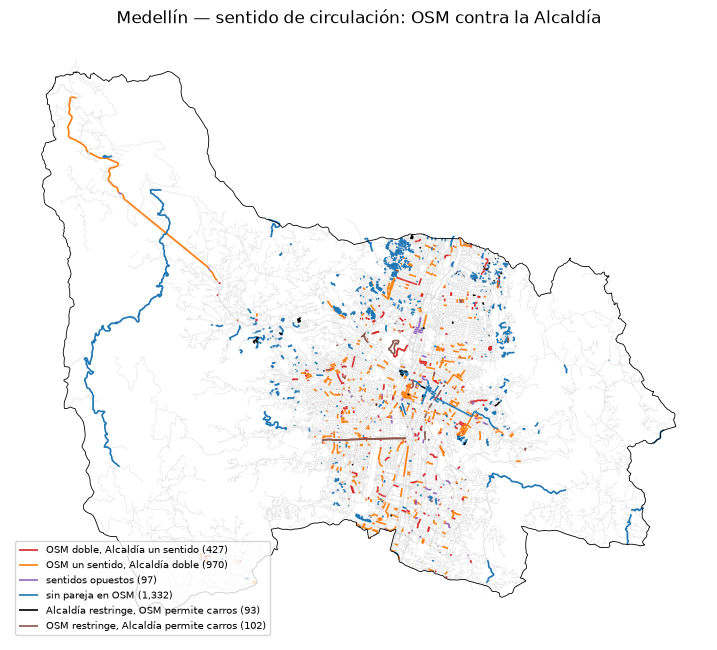

In [10]:
# Celda 10 — Mapa de desacuerdos
import matplotlib.pyplot as plt
if comparacion is not None:
    colores = {"OSM doble, Alcaldía un sentido": "tab:red",
               "OSM un sentido, Alcaldía doble": "tab:orange",
               "sentidos opuestos": "tab:purple",
               "sin pareja en OSM": "tab:blue",
               "Alcaldía restringe, OSM permite carros": "black",
               "OSM restringe, Alcaldía permite carros": "tab:brown"}
    fig, ax = plt.subplots(figsize=(9, 10))
    veh.plot(ax=ax, color="0.85", linewidth=0.3)
    for cat, col in colores.items():
        sub = comparacion[comparacion["categoria"] == cat]
        if len(sub):
            sub.plot(ax=ax, color=col, linewidth=1.2, label=f"{cat} ({len(sub):,})")
    if limite is not None:
        limite.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.legend(loc="lower left", fontsize=7); ax.set_axis_off()
    ax.set_title("Medellín — sentido de circulación: OSM contra la Alcaldía")
    ruta_png = SALIDA / "mapa_desacuerdos.png"
    assert not ruta_png.exists()
    fig.savefig(ruta_png, dpi=200, bbox_inches="tight"); ESCRITOS.append(ruta_png)
    plt.show()


In [11]:
# Celda 11 — Pruebas (verificación independiente de lo anterior)
pr = []
def reg(cod, nombre, ok, detalle):
    pr.append({"prueba": cod, "nombre": nombre, "resultado": "PASA" if ok else "FALLA", "detalle": detalle})

reg("P1", "Overpass respondió sin aviso de error y con datos",
    not datos.get("remark") and len(datos["elements"]) > 0, f"{len(datos['elements']):,} elementos")
reg("P2", "Crudo en disco = crudo en memoria",
    sha256_archivo(SALIDA / "osm_crudo_medellin.json") == manifiesto_osm["sha256"], manifiesto_osm["sha256"][:12] + "…")
reg("P3", "IDs de vía OSM únicos", osm["osm_id"].is_unique, f"{osm['osm_id'].duplicated().sum()} duplicados")
razon = osm["long_m"].sum() / osm["long_geodesica_m"].sum()
reg("P4", "Longitud proyectada vs geodésica (cálculo independiente)", 0.99 < razon < 1.01, f"razón {razon:.5f}")
suma = sum(tot.values)
reg("P5", "Cobertura de sentido suma el total vehicular", abs(suma - veh["long_m"].sum() / 1000) < 0.01,
    f"{suma:,.2f} km vs {veh['long_m'].sum()/1000:,.2f} km")
if comparacion is not None:
    reg("P6", "Comparación: cada tramo de la Alcaldía clasificado una sola vez",
        len(comparacion) == len(alc), f"{len(comparacion):,} clasificados de {len(alc):,}")
pruebas = pd.DataFrame(pr)
print(pruebas.to_string(index=False))
guardar_csv(pruebas, "pruebas.csv")


prueba                                                          nombre resultado                       detalle
    P1               Overpass respondió sin aviso de error y con datos      PASA              59,064 elementos
    P2                               Crudo en disco = crudo en memoria      PASA                 df94efc8068b…
    P3                                           IDs de vía OSM únicos      PASA                  0 duplicados
    P4        Longitud proyectada vs geodésica (cálculo independiente)      PASA                 razón 1.00021
    P5                    Cobertura de sentido suma el total vehicular      PASA    3,226.32 km vs 3,226.32 km
    P6 Comparación: cada tramo de la Alcaldía clasificado una sola vez      PASA 24,578 clasificados de 24,578


WindowsPath('f:/Tesis/Grafo Bogotá/salidas_medellin_prueba_osm/20260925_011846/pruebas.csv')

In [12]:
# Celda 12 — Resumen para la reunión
km_veh = veh["long_m"].sum() / 1000
km_decl = veh.loc[veh["fuente_sentido"].str.startswith(("declarado", "implícito")), "long_m"].sum() / 1000
princ = veh[veh["grupo"].str.startswith("1")]
km_princ_decl = princ.loc[princ["fuente_sentido"].str.startswith(("declarado", "implícito")), "long_m"].sum() / 1000

lineas = [
    "# Prueba OSM — Medellín", "",
    f"- Ejecución: {EJECUCION}",
    f"- Estado del mapa OSM: {fecha_osm}",
    f"- Huella del crudo OSM: {manifiesto_osm['sha256']}",
    f"- Límite: {FUENTE_LIMITE}", "",
    "## Red de OSM",
    f"- Vías vehiculares sin restricción: {len(veh):,} ({km_veh:,.1f} km)",
    f"- Con sentido declarado o implícito: {km_decl:,.1f} km ({km_decl/km_veh:.1%})",
    f"- Vías principales con sentido declarado o implícito: {km_princ_decl/max(princ['long_m'].sum()/1000, 1e-9):.1%}",
    f"- Restricciones de giro: {len(rels):,}",
]
if comparacion is not None:
    n = len(comparacion)
    coinc = int(comparacion["categoria"].isin(["coinciden", "restringido en ambas"]).sum())
    lineas += ["", "## Contra la Alcaldía",
               f"- Tramos comparados: {n:,}",
               f"- Coinciden en sentido: {coinc:,} ({coinc/n:.1%})"]
    for _, fila in resumen_comp.iterrows():
        lineas.append(f"- {fila['categoria']}: {fila['tramos']:,} tramos, {fila['km']:,.1f} km")
lineas += ["", "## Pruebas", f"- {int((pruebas['resultado']=='PASA').sum())} de {len(pruebas)} pasan", "",
           "Nota: la capa de la Alcaldía se construyó sobre OSM; la coincidencia no es verificación independiente."]
resumen = "\n".join(lineas)
escribir_nuevo("resumen.md", resumen)

indice = pd.DataFrame([{"archivo": p.name, "sha256": sha256_archivo(p), "bytes": p.stat().st_size} for p in ESCRITOS])
escribir_nuevo("indice_archivos.csv", indice.to_csv(index=False))
print(resumen)
print(f"\nArchivos escritos ({len(indice)+1}) en: {SALIDA}")


# Prueba OSM — Medellín

- Ejecución: 20260925_011846
- Estado del mapa OSM: 2026-09-25T06:17:59Z
- Huella del crudo OSM: df94efc8068bbc0a841dc1f470cbe6f20b5ea9713ebbcef64fe6d62c8294b57c
- Límite: IGAC

## Red de OSM
- Vías vehiculares sin restricción: 26,704 (3,226.3 km)
- Con sentido declarado o implícito: 1,055.2 km (32.7%)
- Vías principales con sentido declarado o implícito: 94.6%
- Restricciones de giro: 987

## Contra la Alcaldía
- Tramos comparados: 24,578
- Coinciden en sentido: 21,045 (85.6%)
- coinciden: 21,045 tramos, 2,026.8 km
- sin pareja en OSM: 1,332 tramos, 127.4 km
- OSM un sentido, Alcaldía doble: 970 tramos, 82.8 km
- ángulo ambiguo (cruce o curva): 512 tramos, 20.3 km
- OSM doble, Alcaldía un sentido: 427 tramos, 29.3 km
- OSM restringe, Alcaldía permite carros: 102 tramos, 13.4 km
- sentidos opuestos: 97 tramos, 7.8 km
- Alcaldía restringe, OSM permite carros: 93 tramos, 4.8 km

## Pruebas
- 6 de 6 pasan

Nota: la capa de la Alcaldía se construyó sobre OSM; la co

In [13]:
# Celda 13 — Diagnóstico de los desacuerdos (no modifica nada anterior)
GRUPOS_NO_VEH = {"footway": "peatonal", "pedestrian": "peatonal", "steps": "escaleras",
                 "path": "sendero", "cycleway": "ciclorruta", "corridor": "peatonal"}

# 1) ¿Qué hay en OSM donde la comparación no encontró pareja?
todas = osm_med.reset_index(drop=True)
arbol_todas = STRtree(todas.geometry.values)
sp = comparacion[comparacion["categoria"] == "sin pareja en OSM"]
encontrado = []
for f in sp.itertuples():
    m = f.geometry.interpolate(0.5, normalized=True)
    c = arbol_todas.query(m.buffer(DIST_EMPAREJAMIENTO_M), predicate="intersects")
    if len(c) == 0:
        encontrado.append("nada en OSM")
    else:
        h = todas.iloc[min(c, key=lambda k: todas.geometry.iloc[k].distance(m))]["highway"]
        encontrado.append(GRUPOS_NO_VEH.get(h, f"otro ({h})"))
sp_diag = pd.DataFrame({"en_osm": encontrado,
                        "oneway_alc": sp["oneway_alc"].fillna("SIN DATO").values,
                        "long_m": sp["long_m"].values})
tab1 = pd.crosstab(sp_diag["en_osm"], sp_diag["oneway_alc"], margins=True)
print("1) 'Sin pareja': qué hay en OSM, según lo que dice la Alcaldía\n")
print(tab1.to_string())
guardar_csv(tab1.reset_index(), "diag_sin_pareja.csv")

# 2) ¿Los desacuerdos de sentido son avenidas con dos calzadas en OSM?
def sentido_en_marco_alc(o, m, g):
    dif = abs((rumbo(g, g.length / 2) - rumbo(o.geometry, o.geometry.project(m)) + 180) % 360 - 180)
    if 45 <= dif <= 135 or o["sentido"] not in ("uno_adelante", "uno_atras", "doble"):
        return None
    s = o["sentido"]
    if s != "doble" and dif > 135:
        s = "uno_atras" if s == "uno_adelante" else "uno_adelante"
    return s

filas_diag = []
for cat in ["OSM un sentido, Alcaldía doble", "sentidos opuestos", "OSM doble, Alcaldía un sentido"]:
    sub = comparacion[comparacion["categoria"] == cat]
    for f in sub.itertuples():
        g = f.geometry; m = g.interpolate(0.5, normalized=True)
        c = arbol.query(m.buffer(25.0), predicate="intersects")
        sentidos = {sentido_en_marco_alc(base.iloc[k], m, g) for k in c} - {None}
        dos_calzadas = {"uno_adelante", "uno_atras"} <= sentidos
        filas_diag.append({"categoria": cat, "highway_osm": f.highway_osm, "long_m": f.long_m,
                           "diagnostico": "dos calzadas en OSM (probable falso desacuerdo)"
                                          if dos_calzadas else "desacuerdo real probable"})
diag2 = pd.DataFrame(filas_diag)
tab2 = (diag2.groupby(["categoria", "diagnostico"])
             .agg(tramos=("long_m", "size"), km=("long_m", "sum"))
             .assign(km=lambda t: (t["km"] / 1000).round(1)).reset_index())
print("\n2) Desacuerdos de sentido: ¿avenidas con separador?\n")
print(tab2.to_string(index=False))
print("\nTipo de vía en OSM de los desacuerdos reales probables:")
print(diag2[diag2["diagnostico"].str.startswith("desacuerdo")]
      .groupby(["categoria", "highway_osm"]).size().rename("tramos")
      .sort_values(ascending=False).head(15).to_string())
guardar_csv(tab2, "diag_desacuerdos_sentido.csv")

1) 'Sin pareja': qué hay en OSM, según lo que dice la Alcaldía

oneway_alc             DW  FT    N  SIN DATO  TF   All
en_osm                                                
ciclorruta              0   2    0         0   0     2
escaleras             122   0   15         1   0   138
nada en OSM           252   8   31         3   1   295
otro (construction)     0   1    0         0   0     1
otro (ladder)           3   0    0         0   0     3
peatonal              614  43  158         1   2   818
sendero                72   0    3         0   0    75
All                  1063  54  207         5   3  1332

2) Desacuerdos de sentido: ¿avenidas con separador?

                     categoria                                     diagnostico  tramos   km
OSM doble, Alcaldía un sentido                        desacuerdo real probable     382 27.8
OSM doble, Alcaldía un sentido dos calzadas en OSM (probable falso desacuerdo)      45  1.5
OSM un sentido, Alcaldía doble                        de

WindowsPath('f:/Tesis/Grafo Bogotá/salidas_medellin_prueba_osm/20260925_011846/diag_desacuerdos_sentido.csv')

In [14]:
# Celda 14 — Muestra de 50 desacuerdos para revisar a mano en Mapillary
# Solo lee lo que ya está en memoria (celdas 9 y 13) y escribe archivos NUEVOS en la carpeta de esta ejecución.
SEMILLA = 20260924   # fija: cualquiera que corra esto obtiene exactamente la misma muestra
TAMANO_ESTRATO = {   # asignación fija y declarada (suma 50); mínimo 5 para que ningún tipo quede sin ver
    "A · OSM un sentido, Alcaldía doble":             14,
    "B · OSM doble, Alcaldía un sentido":             12,
    "C · Sentidos opuestos":                           5,
    "D · Alcaldía calle, OSM escaleras":               8,
    "E · Alcaldía calle, OSM peatonal o sendero":     11,
}

# Recuperar a qué tramo de 'comparacion' corresponde cada fila de los diagnósticos de la celda 13
ORDEN_C13 = ["OSM un sentido, Alcaldía doble", "sentidos opuestos", "OSM doble, Alcaldía un sentido"]
idx_diag2 = np.concatenate([comparacion.index[comparacion["categoria"] == c].values for c in ORDEN_C13])
assert len(idx_diag2) == len(diag2), "diag2 no corresponde a 'comparacion': vuelve a correr las celdas 9 y 13"
diag2_i = diag2.assign(idx=idx_diag2)
sp_i = sp_diag.assign(idx=sp.index.values)

reales = diag2_i[diag2_i["diagnostico"].str.startswith("desacuerdo")]
peat = sp_i[sp_i["oneway_alc"].isin(["DW", "FT", "TF", "SIN DATO"])]
poblacion = {
    "A · OSM un sentido, Alcaldía doble":         reales.loc[reales["categoria"] == "OSM un sentido, Alcaldía doble", "idx"],
    "B · OSM doble, Alcaldía un sentido":         reales.loc[reales["categoria"] == "OSM doble, Alcaldía un sentido", "idx"],
    "C · Sentidos opuestos":                      reales.loc[reales["categoria"] == "sentidos opuestos", "idx"],
    "D · Alcaldía calle, OSM escaleras":          peat.loc[peat["en_osm"] == "escaleras", "idx"],
    "E · Alcaldía calle, OSM peatonal o sendero": peat.loc[peat["en_osm"].isin(["peatonal", "sendero"]), "idx"],
}

def rumbo_brujula(linea, invertir=False):
    """Hacia dónde va la línea en su punto medio, como punto cardinal (N, NE, E...)."""
    ang = rumbo(linea, linea.length / 2)              # 0 = este, antihorario
    az = (90 - ang + (180 if invertir else 0)) % 360  # 0 = norte, horario
    return ["N", "NE", "E", "SE", "S", "SO", "O", "NO"][int(((az + 22.5) % 360) // 45)]

osm_por_id = base.set_index("osm_id")
filas = []
for estrato, idxs in poblacion.items():
    n = min(TAMANO_ESTRATO[estrato], len(idxs))
    elegidos = pd.Series(sorted(idxs)).sample(n=n, random_state=SEMILLA) if n else []
    for i in elegidos:
        f = comparacion.loc[i]
        g = f.geometry
        ow = f["oneway_alc"]
        if ow == "FT":   circ_alc = f"solo hacia el {rumbo_brujula(g)}"
        elif ow == "TF": circ_alc = f"solo hacia el {rumbo_brujula(g, invertir=True)}"
        elif ow == "N":  circ_alc = "prohibida para carros"
        else:            circ_alc = "doble vía"
        if estrato.startswith(("D", "E")):
            circ_osm = "peatonal / escaleras / sendero (sin carros)"
            osm_link = ""
        else:
            o = osm_por_id.loc[f["osm_id"]]
            s = sentido_en_marco_alc(o, g.interpolate(0.5, normalized=True), g)
            circ_osm = {"uno_adelante": f"solo hacia el {rumbo_brujula(g)}",
                        "uno_atras": f"solo hacia el {rumbo_brujula(g, invertir=True)}",
                        "doble": "doble vía"}.get(s, "no determinado")
            osm_link = f"https://www.openstreetmap.org/way/{int(f['osm_id'])}/history"
        lon, lat = gpd.GeoSeries([g.interpolate(0.5, normalized=True)], crs=EPSG_METRICO).to_crs(4326).iloc[0].coords[0]
        filas.append({
            "n": 0, "estrato": estrato, "peso_estrato": round(len(idxs) / n, 2),
            "id_svial": f["id_svial"], "nombre_alcaldia": f["nombre_alc"],
            "circulacion_segun_alcaldia": circ_alc, "circulacion_segun_osm": circ_osm,
            "highway_osm": f.get("highway_osm"), "largo_m": round(g.length, 1),
            "lat": round(lat, 6), "lon": round(lon, 6),
            "mapillary": f"https://www.mapillary.com/app/?lat={lat:.6f}&lng={lon:.6f}&z=19",
            "osm_historial": osm_link,
            # --- columnas para llenar a mano ---
            "veredicto": "", "fecha_imagen": "", "evidencia": "", "revisor": "",
        })
muestra = pd.DataFrame(filas)
muestra["n"] = range(1, len(muestra) + 1)

print(f"Muestra: {len(muestra)} tramos (semilla {SEMILLA})\n")
print(muestra.groupby("estrato").agg(en_muestra=("n", "size"), peso=("peso_estrato", "first")).to_string())

# Excel abre bien los acentos si el CSV lleva la marca UTF-8 al inicio
escribir_nuevo("muestra_validacion_mapillary.csv", "\ufeff" + muestra.to_csv(index=False))
ruta_pts = SALIDA / "muestra_validacion_mapillary.gpkg"
assert not ruta_pts.exists()
gpd.GeoDataFrame(muestra, geometry=gpd.points_from_xy(muestra["lon"], muestra["lat"]), crs=4326) \
   .to_file(ruta_pts, layer="muestra", driver="GPKG")
ESCRITOS.append(ruta_pts)

PROTOCOLO = f"""# Protocolo de revisión — muestra de desacuerdos OSM vs Alcaldía (Medellín)

Muestra: {len(muestra)} tramos, semilla {SEMILLA}, ejecución {EJECUCION}.
Paso manual declarado: la revisión se hace a ojo sobre imágenes de Mapillary (abiertas, CC BY-SA).

## Para cada fila
1. Abrir el enlace de `mapillary` y buscar la foto más cercana al punto, preferiblemente de 2023 en adelante.
2. Mirar: señales de «una vía» o flechas, carros parqueados o circulando (hacia dónde miran),
   escaleras, bolardos, rejas o andenes que impidan el paso de carros.
3. Llenar `veredicto` con UNA de estas opciones:
   - `acierta_alcaldia`
   - `acierta_osm`
   - `ninguna` (la realidad no coincide con ninguna de las dos)
   - `sin_imagen` (no hay foto útil a menos de ~30 m o no se ve)
4. Llenar `fecha_imagen` (AAAA-MM) y en `evidencia` una frase corta: «señal una vía hacia el N», «escaleras», etc.

## Cómo se usa el resultado
Cada estrato se resume por separado. Para estimar cuántos desacuerdos de toda la ciudad acierta cada fuente,
cada fila vale lo que indica `peso_estrato` (tramos que representa).
Con 50 tramos la estimación es orientativa: sirve para saber qué fuente acierta más, no para dar un porcentaje exacto.
"""
escribir_nuevo("protocolo_revision_mapillary.md", PROTOCOLO)
print(f"\nArchivos nuevos en {SALIDA}:")
print("  muestra_validacion_mapillary.csv  (para llenar en Excel)")
print("  muestra_validacion_mapillary.gpkg (los 50 puntos, para QGIS)")
print("  protocolo_revision_mapillary.md   (instrucciones de revisión)")

Muestra: 50 tramos (semilla 20260924)

                                            en_muestra   peso
estrato                                                      
A · OSM un sentido, Alcaldía doble                  14  58.00
B · OSM doble, Alcaldía un sentido                  12  31.83
C · Sentidos opuestos                                5   9.60
D · Alcaldía calle, OSM escaleras                    8  15.38
E · Alcaldía calle, OSM peatonal o sendero          11  66.55

Archivos nuevos en f:\Tesis\Grafo Bogotá\salidas_medellin_prueba_osm\20260925_011846:
  muestra_validacion_mapillary.csv  (para llenar en Excel)
  muestra_validacion_mapillary.gpkg (los 50 puntos, para QGIS)
  protocolo_revision_mapillary.md   (instrucciones de revisión)


In [15]:
# Celda 15 — Lista de exclusión: tramos de la Alcaldía que OSM identifica como no aptos para carros
# Solo lee lo que ya está en memoria (celdas 1 a 9) y escribe archivos NUEVOS en la carpeta de esta ejecución.
#
# Criterio (conservador). Se evalúa en el centro del tramo, recortando hasta 10 m en cada extremo,
# para que las calles que tocan sus puntas (p. ej. las dos calles que une una escalera) no cuenten:
#   - en la celda 9 el tramo quedó «sin pareja» o en «ángulo ambiguo» (una escalera corta entre dos calles
#     cae ahí, porque su punto medio queda cerca de las calles que une), y la Alcaldía no lo restringe ya ('N');
#   - como mucho el 25 % del centro del tramo queda a menos de 5 m de una vía para carros de OSM;
#   - al menos el 60 % del centro queda a menos de 10 m de escaleras, peatonal o sendero de OSM.
# Así, una calle real a la que OSM le dibujó el andén aparte NO se excluye (la vía está encima).
from shapely.ops import substring

NO_VEH = {"steps": "escaleras", "ladder": "escaleras", "footway": "peatonal", "pedestrian": "peatonal",
          "corridor": "peatonal", "path": "sendero", "cycleway": "ciclorruta"}
BUF_VEH_M, MAX_COB_VEH = 5.0, 0.25
BUF_NV_M,  MIN_COB_NV  = 10.0, 0.60
RECORTE_EXTREMOS_M, RECORTE_MAX_FRAC = 10.0, 0.30   # se recorta min(10 m, 30 % del largo) en cada punta

nv = osm_med[osm_med["highway"].isin(NO_VEH)].reset_index(drop=True)
arbol_nv = STRtree(nv.geometry.values)

def cobertura(nucleo, geoms, buffer_m):
    if len(geoms) == 0 or nucleo.length == 0:
        return 0.0
    zona = unir(gpd.GeoSeries(list(geoms)).buffer(buffer_m))
    return nucleo.intersection(zona).length / nucleo.length

CATEGORIAS_CANDIDATAS = ["sin pareja en OSM", "ángulo ambiguo (cruce o curva)"]
candidatos = comparacion[comparacion["categoria"].isin(CATEGORIAS_CANDIDATAS)
                         & (comparacion["oneway_alc"].fillna("") != "N")]
filas = []
for f in candidatos.itertuples():
    g = f.geometry
    d0 = min(RECORTE_EXTREMOS_M, RECORTE_MAX_FRAC * g.length)
    nucleo = substring(g, d0, g.length - d0)
    iv = arbol.query(nucleo.buffer(BUF_VEH_M), predicate="intersects")
    inv = arbol_nv.query(nucleo.buffer(BUF_NV_M), predicate="intersects")
    c_veh = cobertura(nucleo, base.geometry.iloc[iv].values, BUF_VEH_M)
    c_nv = cobertura(nucleo, nv.geometry.iloc[inv].values, BUF_NV_M)
    tipo = None
    if len(inv):
        aporte = {}
        for k in inv:
            t = NO_VEH[nv.iloc[k]["highway"]]
            aporte[t] = aporte.get(t, 0) + nucleo.intersection(nv.geometry.iloc[k].buffer(BUF_NV_M)).length
        tipo = max(aporte, key=aporte.get)
    excluir = c_veh <= MAX_COB_VEH and c_nv >= MIN_COB_NV
    if excluir:
        motivo = tipo
    elif c_veh > MAX_COB_VEH:
        motivo = "hay vía para carros de OSM encima"
    elif c_nv == 0:
        motivo = "sin evidencia en OSM"
    else:
        motivo = f"evidencia insuficiente ({tipo})"
    filas.append({"id_svial": int(f.id_svial), "categoria_celda9": f.categoria,
                  "oneway_alc": f.oneway_alc, "nombre_alc": f.nombre_alc,
                  "largo_m": round(g.length, 1), "cob_vehicular": round(c_veh, 3),
                  "cob_no_vehicular": round(c_nv, 3), "decision": "excluir" if excluir else "conservar",
                  "motivo": motivo, "geometry": g})
evaluacion = gpd.GeoDataFrame(filas, geometry="geometry", crs=EPSG_METRICO)

print(f"Evaluados: {len(evaluacion):,} tramos de la Alcaldía ('sin pareja' o 'ángulo ambiguo', sin contar los 'N')\n")
print(evaluacion.groupby(["categoria_celda9", "decision", "motivo"])
      .agg(tramos=("largo_m", "size"), km=("largo_m", "sum"))
      .assign(km=lambda t: (t["km"] / 1000).round(2)).to_string())

exclusion = (evaluacion[evaluacion["decision"] == "excluir"]
             .drop(columns=["geometry", "decision"]).sort_values("id_svial").reset_index(drop=True))
assert exclusion["id_svial"].is_unique, "id_svial repetido en la lista de exclusión"

guardar_csv(evaluacion.drop(columns="geometry"), "evaluacion_exclusion_no_vehicular.csv")
ruta_eval_gpkg = SALIDA / "evaluacion_exclusion_no_vehicular.gpkg"
assert not ruta_eval_gpkg.exists()
evaluacion.to_file(ruta_eval_gpkg, layer="evaluacion", driver="GPKG"); ESCRITOS.append(ruta_eval_gpkg)

ruta_excl = escribir_nuevo("D2M_exclusion_no_vehicular_osm.csv", "\ufeff" + exclusion.to_csv(index=False))
sha_excl = sha256_archivo(ruta_excl)
manifiesto_excl = {
    "descripcion": "Tramos de la capa Sentido vial (Alcaldía) que OSM identifica como no aptos para carros",
    "archivo_csv": ruta_excl.name, "sha256_csv": sha_excl,
    "n_tramos": int(len(exclusion)), "km": round(float(exclusion["largo_m"].sum()) / 1000, 3),
    "por_motivo": exclusion["motivo"].value_counts().to_dict(),
    "hash_conjunto_alcaldia": man_alc["hash_conjunto"],
    "osm_sha256_crudo": manifiesto_osm["sha256"],
    "osm_estado_del_mapa": manifiesto_osm["estado_del_mapa_osm"],
    "criterio": {"categorias_candidatas": CATEGORIAS_CANDIDATAS, "recorte_extremos_m": RECORTE_EXTREMOS_M,
                 "recorte_max_frac": RECORTE_MAX_FRAC, "buffer_vehicular_m": BUF_VEH_M,
                 "max_cobertura_vehicular": MAX_COB_VEH, "buffer_no_vehicular_m": BUF_NV_M,
                 "min_cobertura_no_vehicular": MIN_COB_NV, "tipos_no_vehiculares": NO_VEH},
    "ejecucion": EJECUCION,
}
escribir_nuevo("D2M_exclusion_no_vehicular_osm_manifiesto.json",
               json.dumps(manifiesto_excl, ensure_ascii=False, indent=2))

print(f"\nA excluir: {len(exclusion):,} tramos, {exclusion['largo_m'].sum()/1000:,.2f} km")
print(exclusion["motivo"].value_counts().to_string())
print("\n>>> Copiá estas dos líneas al final de constantes_d1.py <<<")
print(f'RUTA_EXCLUSION_OSM_MED = r"{ruta_excl}"')
print(f'SHA256_EXCLUSION_OSM_MED = "{sha_excl}"')

Evaluados: 1,637 tramos de la Alcaldía ('sin pareja' o 'ángulo ambiguo', sin contar los 'N')

                                                                             tramos     km
categoria_celda9               decision  motivo                                           
sin pareja en OSM              conservar evidencia insuficiente (escaleras)      12   0.55
                                         evidencia insuficiente (peatonal)       40   2.60
                                         evidencia insuficiente (sendero)        11   2.26
                                         hay vía para carros de OSM encima       48  33.38
                                         sin evidencia en OSM                   178  14.17
                               excluir   escaleras                              117   7.12
                                         peatonal                               654  41.59
                                         sendero                                 65  10

## Cómo leer el resultado

**La cifra que decide** es el porcentaje de vías principales con sentido declarado o implícito (celda 12). En OSM, una calle sin etiqueta de sentido se toma como doble vía; eso es correcto para la mayoría de calles de barrio, pero es un problema si le falta a una vía de un solo sentido.

**Contra la Alcaldía**, la categoría clave es **«OSM doble, Alcaldía un sentido»**: son calles que OSM deja recorrer en los dos sentidos cuando no se puede. La celda 9 muestra si es porque OSM no tiene la etiqueta (le falta información) o porque la declara mal (información equivocada).

- Si esa categoría es pequeña y los desacuerdos se concentran en pocas zonas: OSM sirve, y los desacuerdos se reportan como resultado.
- Si es grande o está repartida por toda la ciudad: OSM necesitaría correcciones antes de rutear, y conviene llevar el número a tutoría.

**Recordatorio:** la Alcaldía construyó su capa sobre OSM. Una coincidencia alta puede ser copia, no confirmación.